<a href="https://colab.research.google.com/github/Babatems/wall-material-cnn-glcm/blob/main/CNN_GLCM_Fusion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CNN–GLCM Fusion: Inception V3 vs ResNet-50
**Wall Material Condition Recognition on Limited Data** — Temiloluwa Inumoh, MSc ACS&S, University of Winnipeg

Replicates the fusion model of Mengiste et al. (2024) [JCCE 38(1) 04023036] and compares it with a ResNet-50 backbone.

**Run cells top to bottom.** Before you start: *Runtime → Change runtime type → T4 GPU*.

| Config | Backbone | GLCM branch | Aim |
|---|---|---|---|
| `inception_fusion` | Inception V3 | yes | A1 replication |
| `inception_cnn` | Inception V3 | no | A3 ablation |
| `resnet_fusion` | ResNet-50 | yes | A2 |
| `resnet_cnn` | ResNet-50 | no | A3 ablation |

In [17]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Setup

In [2]:
# Mount Google Drive so data and results survive Colab disconnects
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [18]:
!pip -q install scikit-image statsmodels

In [19]:
import os, json, random, glob, time
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from skimage.feature import graycomatrix, graycoprops
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from statsmodels.stats.contingency_tables import mcnemar

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', DEVICE, '| torch', torch.__version__)

Device: cuda | torch 2.11.0+cu130


In [20]:
!nvidia-smi
print(DEVICE)

Thu Oct 22 02:38:28 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   72C    P0             32W /   70W |     903MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Configuration — every choice in one place
Anything marked **ASSUMED** is not stated in the paper (or not yet confirmed by the authors).
If the authors reply with their settings, change it here and re-run. This dictionary is saved
alongside your results, so your report can list exactly what was used.

In [21]:
PROJECT_DIR = '/content/drive/MyDrive/wall-material-project'   # change if you used another folder
DATA_DIR    = f'{PROJECT_DIR}/data'                             # unzipped Mendeley dataset goes here
RESULTS_DIR = f'{PROJECT_DIR}/results'
os.makedirs(RESULTS_DIR, exist_ok=True)

CONFIG = {
    # --- Data split (paper: 80/20) ---
    'test_size': 0.20,
    'split_seed': 42,                       # fixed: SAME split for every config and training seed
    # --- GLCM (ASSUMED: paper's exact properties/distances/angles not yet confirmed) ---
    'glcm_size': 256,                       # grayscale image resized to 256x256 before GLCM
    'glcm_levels': 64,                      # gray levels after quantisation
    'glcm_distances': [1, 2, 3],
    'glcm_angles_deg': [0, 45, 90, 135],
    'glcm_props': ['contrast', 'dissimilarity', 'homogeneity', 'energy', 'correlation', 'ASM'],
    # --- Architecture (paper: CNN -> 1024, GLCM -> 256, concat 1280) ---
    'cnn_dim': 1024,
    'glcm_dim': 256,
    'head_hidden': 256,                     # ASSUMED
    'dropout': 0.3,                         # ASSUMED
    # --- Training (ASSUMED) ---
    'batch_size': 16,
    'epochs_frozen': 15,                    # stage 1: backbone frozen, train new layers only
    'epochs_finetune': 15,                  # stage 2: also unfreeze the last backbone block
    'lr_head': 1e-3,
    'lr_finetune': 1e-4,
    'weight_decay': 1e-4,
    # --- Augmentation, training images only (ASSUMED) ---
    'aug_rotation_deg': 15,
    'aug_crop_scale': (0.8, 1.0),
    'aug_brightness': 0.2,
    'aug_contrast': 0.2,
    # --- Repeats ---
    'train_seeds': [0, 1, 2, 3, 4],
}
INPUT_SIZE = {'inception': 299, 'resnet': 224}   # native input size of each backbone

with open(f'{RESULTS_DIR}/config.json', 'w') as f:
    json.dump(CONFIG, f, indent=2)

## 3. Load the dataset and check the counts
Expected: **208 images, 7 classes** — CMU wall 24, chiseled concrete 49, concrete 18, gypsum 26,
mesh 25, first coat plaster 37, second coat plaster 29. If the numbers differ, stop and check the folder structure.

In [22]:
EXTS = ('.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff')
paths = [p for p in glob.glob(f'{DATA_DIR}/**/*', recursive=True) if p.lower().endswith(EXTS)]
df = pd.DataFrame({'path': sorted(paths)})
df['label_name'] = df['path'].apply(lambda p: os.path.basename(os.path.dirname(p)))  # class = parent folder

CLASSES = sorted(df['label_name'].unique())
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}
df['label'] = df['label_name'].map(CLASS_TO_IDX)

print('Total images:', len(df))
print(df['label_name'].value_counts().sort_index())

Total images: 208
label_name
CMU wall               24
Chiseled concrete      49
Concrete               18
First coat plaster     37
Gypsum                 26
Mesh                   25
Second coat plaster    29
Name: count, dtype: int64


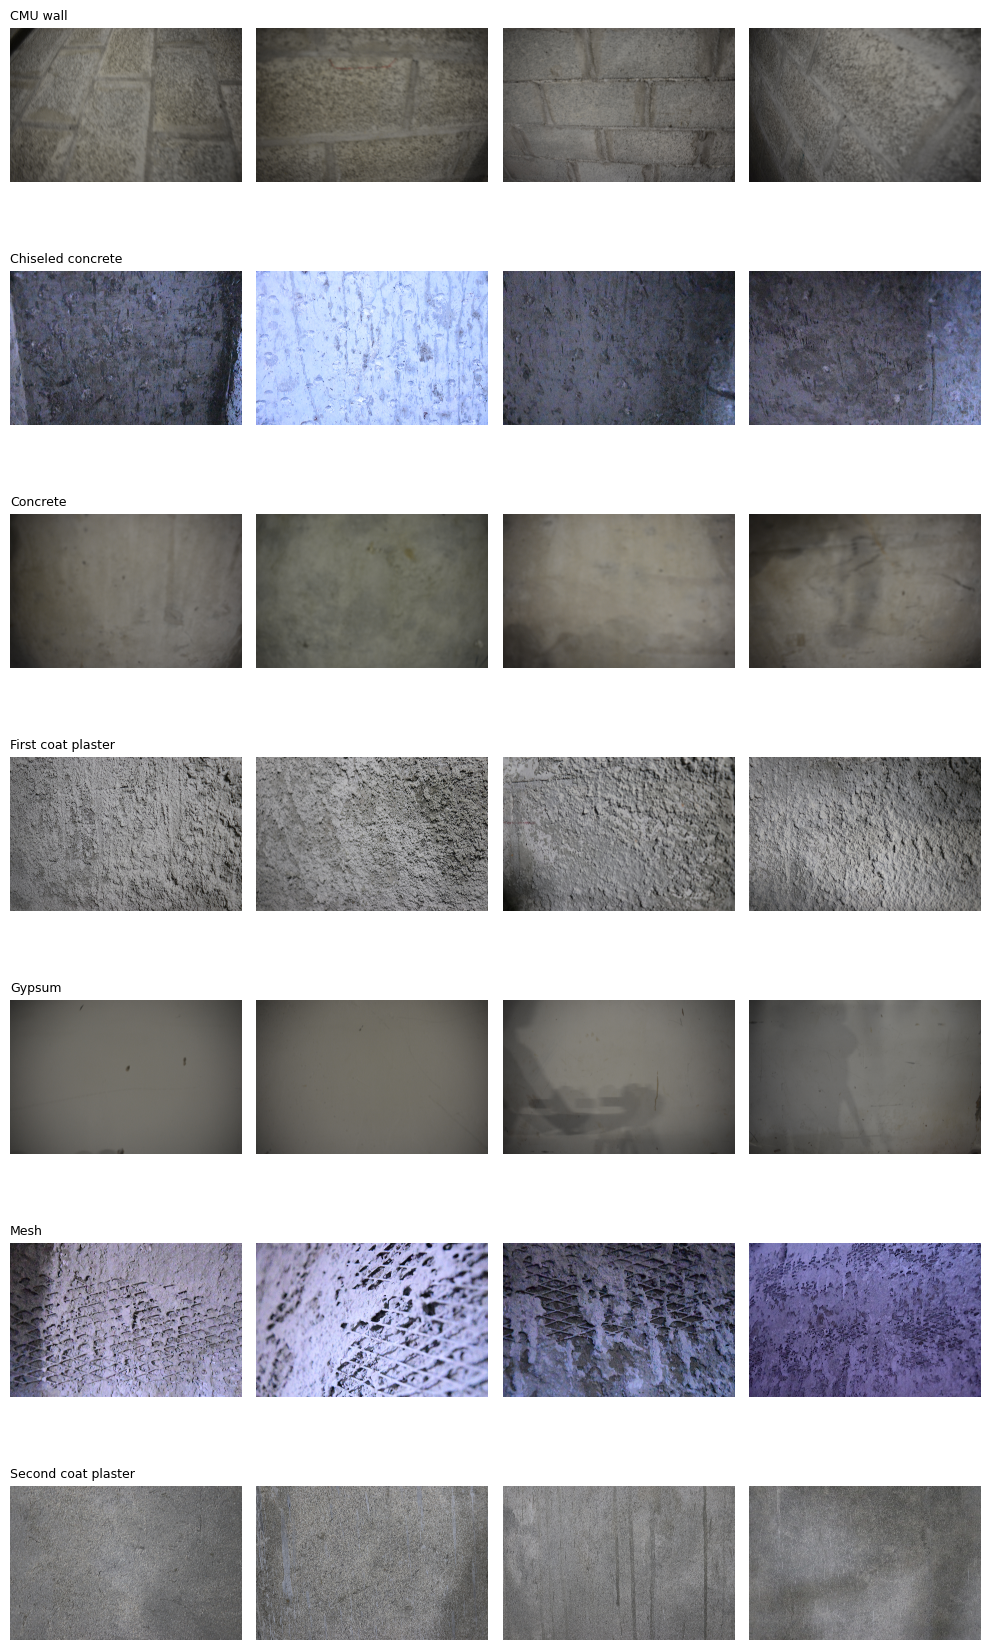

In [23]:
# Look at a few images per class (useful for the data audit and for spotting obvious label problems)
fig, axes = plt.subplots(len(CLASSES), 4, figsize=(10, 2.5 * len(CLASSES)))
for r, c in enumerate(CLASSES):
    sample = df[df['label_name'] == c].sample(min(4, (df['label_name'] == c).sum()), random_state=0)
    for k, ax in enumerate(axes[r]):
        ax.axis('off')
        if k < len(sample):
            ax.imshow(Image.open(sample.iloc[k]['path']).convert('RGB'))
            if k == 0: ax.set_title(c, loc='left', fontsize=9)
plt.tight_layout(); plt.show()

## 4. Fixed 80/20 stratified split (saved, reused by every run)

In [24]:
split_file = f'{RESULTS_DIR}/split.csv'
if os.path.exists(split_file):
    df = pd.read_csv(split_file)
    print('Loaded existing split.')
else:
    train_idx, test_idx = train_test_split(df.index, test_size=CONFIG['test_size'],
                                           stratify=df['label'], random_state=CONFIG['split_seed'])
    df['split'] = 'train'
    df.loc[test_idx, 'split'] = 'test'
    df.to_csv(split_file, index=False)
print(pd.crosstab(df['label_name'], df['split']))

Loaded existing split.
split                test  train
label_name                      
CMU wall                5     19
Chiseled concrete      10     39
Concrete                4     14
First coat plaster      7     30
Gypsum                  5     21
Mesh                    5     20
Second coat plaster     6     23


## 5. GLCM texture features
Computed once on the original (non-augmented) image, then standardised with **training-set statistics only**.

In [25]:
def glcm_features(path, cfg=CONFIG):
    img = Image.open(path).convert('L').resize((cfg['glcm_size'], cfg['glcm_size']))
    g = np.asarray(img, dtype=np.float32)
    q = np.floor(g / 256.0 * cfg['glcm_levels']).astype(np.uint8)          # quantise 0..levels-1
    angles = [np.deg2rad(a) for a in cfg['glcm_angles_deg']]
    P = graycomatrix(q, distances=cfg['glcm_distances'], angles=angles,
                     levels=cfg['glcm_levels'], symmetric=True, normed=True)
    feats = [graycoprops(P, prop).ravel() for prop in cfg['glcm_props']]   # props x distances x angles
    return np.nan_to_num(np.concatenate(feats)).astype(np.float32)

glcm_file = f'{RESULTS_DIR}/glcm_features.npy'
if os.path.exists(glcm_file):
    GLCM = np.load(glcm_file)
else:
    GLCM = np.stack([glcm_features(p) for p in df['path']])
    np.save(glcm_file, GLCM)

train_mask = (df['split'] == 'train').values
mu, sd = GLCM[train_mask].mean(0), GLCM[train_mask].std(0) + 1e-8
GLCM_STD = (GLCM - mu) / sd
N_GLCM = GLCM.shape[1]
print('GLCM feature vector length:', N_GLCM)   # 6 props x 3 distances x 4 angles = 72

GLCM feature vector length: 72


## 6. Dataset and augmentation

In [26]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]   # ImageNet normalisation

def make_transforms(size, train, cfg=CONFIG):
    if train:
        return transforms.Compose([
            transforms.RandomResizedCrop(size, scale=cfg['aug_crop_scale']),
            transforms.RandomHorizontalFlip(),
            transforms.RandomRotation(cfg['aug_rotation_deg']),
            transforms.ColorJitter(brightness=cfg['aug_brightness'], contrast=cfg['aug_contrast']),
            transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
    return transforms.Compose([
        transforms.Resize((size, size)),
        transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

# Images are decoded from Drive ONCE, shrunk, and kept in memory (decoding large photos
# from Drive every epoch is what makes training slow). One cache per backbone input size.
_IMG_CACHE = {}
def cached_images(paths, size):
    if size not in _IMG_CACHE:
        shrink = transforms.Resize(int(size * 1.15))      # shorter side ~15% above the crop size
        print(f'Caching {len(df)} images at {size}px (one-time)...')
        _IMG_CACHE[size] = {p: shrink(Image.open(p).convert('RGB')) for p in df['path']}
    return [_IMG_CACHE[size][p] for p in paths]

class WallDataset(Dataset):
    def __init__(self, frame, glcm, tfm, size):
        self.images = cached_images(frame['path'].tolist(), size)
        self.labels = frame['label'].tolist()
        self.glcm = torch.tensor(glcm, dtype=torch.float32)
        self.tfm = tfm
    def __len__(self):
        return len(self.images)
    def __getitem__(self, i):
        return self.tfm(self.images[i]), self.glcm[i], self.labels[i]

## 7. Model — the same head for both backbones
Only the backbone changes between Inception V3 and ResNet-50. `use_glcm=False` removes the texture branch (ablation).

In [27]:
class FusionNet(nn.Module):
    def __init__(self, backbone, use_glcm, n_classes, n_glcm, cfg=CONFIG):
        super().__init__()
        self.use_glcm = use_glcm
        if backbone == 'inception':
            self.backbone = models.inception_v3(weights=models.Inception_V3_Weights.IMAGENET1K_V1)
            self.backbone.aux_logits = False      # pretrained weights require the aux branch at load time;
            self.backbone.AuxLogits = None        # switch it off afterwards so forward() returns one output
            self.last_block = self.backbone.Mixed_7c
        elif backbone == 'resnet':
            self.backbone = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
            self.last_block = self.backbone.layer4
        else:
            raise ValueError(backbone)
        self.backbone.fc = nn.Identity()          # both backbones now output 2048 pooled features

        self.cnn_proj = nn.Sequential(nn.Linear(2048, cfg['cnn_dim']), nn.ReLU(), nn.Dropout(cfg['dropout']))
        in_dim = cfg['cnn_dim']
        if use_glcm:
            self.glcm_net = nn.Sequential(nn.Linear(n_glcm, cfg['glcm_dim']), nn.ReLU(), nn.Dropout(cfg['dropout']))
            in_dim += cfg['glcm_dim']               # 1024 + 256 = 1280
        self.head = nn.Sequential(nn.Linear(in_dim, cfg['head_hidden']), nn.ReLU(),
                                  nn.Dropout(cfg['dropout']), nn.Linear(cfg['head_hidden'], n_classes))
        self.set_stage('frozen')

    def set_stage(self, stage):
        for p in self.backbone.parameters():
            p.requires_grad = False
        if stage == 'finetune':
            for p in self.last_block.parameters():
                p.requires_grad = True

    def forward(self, x, glcm):
        z = self.cnn_proj(self.backbone(x))
        if self.use_glcm:
            z = torch.cat([z, self.glcm_net(glcm)], dim=1)
        return self.head(z)

## 8. Training and evaluation
No validation set is carved out (to match the paper's 80/20 split), so **the test set is never used to pick epochs**:
every run trains for a fixed number of epochs and is evaluated once at the end.

In [28]:
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def run_epochs(model, loader, n_epochs, lr, stage):
    model.set_stage(stage)
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=CONFIG['weight_decay'])
    loss_fn = nn.CrossEntropyLoss()
    for ep in range(n_epochs):
        model.train()
        model.backbone.eval()                      # keep frozen BatchNorm statistics fixed...
        if stage == 'finetune':
            model.last_block.train()               # ...except in the block being fine-tuned
        total = 0.0
        for x, g, y in loader:
            x, g, y = x.to(DEVICE), g.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()
            loss = loss_fn(model(x, g), y)
            loss.backward(); opt.step()
            total += loss.item() * len(y)
        print(f'  [{stage}] epoch {ep+1:02d}/{n_epochs}  loss {total/len(loader.dataset):.4f}')

@torch.no_grad()
def predict(model, loader):
    model.eval()
    preds = []
    for x, g, _ in loader:
        preds.append(model(x.to(DEVICE), g.to(DEVICE)).argmax(1).cpu())
    return torch.cat(preds).numpy()

def train_and_eval(backbone, use_glcm, seed):
    set_seed(seed)
    size = INPUT_SIZE[backbone]
    tr, te = df[df['split'] == 'train'], df[df['split'] == 'test']
    tr_ds = WallDataset(tr, GLCM_STD[tr.index], make_transforms(size, True), size)
    te_ds = WallDataset(te, GLCM_STD[te.index], make_transforms(size, False), size)
    gen = torch.Generator().manual_seed(seed)
    tr_dl = DataLoader(tr_ds, batch_size=CONFIG['batch_size'], shuffle=True, generator=gen, num_workers=2)
    te_dl = DataLoader(te_ds, batch_size=CONFIG['batch_size'], shuffle=False, num_workers=2)

    model = FusionNet(backbone, use_glcm, len(CLASSES), N_GLCM).to(DEVICE)
    run_epochs(model, tr_dl, CONFIG['epochs_frozen'], CONFIG['lr_head'], 'frozen')
    if CONFIG['epochs_finetune'] > 0:
        run_epochs(model, tr_dl, CONFIG['epochs_finetune'], CONFIG['lr_finetune'], 'finetune')

    y_true, y_pred = te['label'].values, predict(model, te_dl)
    return y_true, y_pred, te['path'].values

## 9. Quick test first — one run of the replication
Run this before the full loop to check everything works end to end.

In [29]:
t0 = time.time()
y_true, y_pred, _ = train_and_eval('inception', use_glcm=True, seed=0)
print(f'\nAccuracy {accuracy_score(y_true, y_pred):.3f} | macro-F1 {f1_score(y_true, y_pred, average="macro"):.3f} '
      f'| {(time.time()-t0)/60:.1f} min')
print(classification_report(y_true, y_pred, target_names=CLASSES, zero_division=0))

Caching 208 images at 299px (one-time)...
  [frozen] epoch 01/15  loss 1.6651
  [frozen] epoch 02/15  loss 0.8465
  [frozen] epoch 03/15  loss 0.4923
  [frozen] epoch 04/15  loss 0.2887
  [frozen] epoch 05/15  loss 0.2531
  [frozen] epoch 06/15  loss 0.1264
  [frozen] epoch 07/15  loss 0.1277
  [frozen] epoch 08/15  loss 0.1028
  [frozen] epoch 09/15  loss 0.1258
  [frozen] epoch 10/15  loss 0.1238
  [frozen] epoch 11/15  loss 0.0926
  [frozen] epoch 12/15  loss 0.0844
  [frozen] epoch 13/15  loss 0.0925
  [frozen] epoch 14/15  loss 0.1004
  [frozen] epoch 15/15  loss 0.0511
  [finetune] epoch 01/15  loss 0.1529
  [finetune] epoch 02/15  loss 0.0372
  [finetune] epoch 03/15  loss 0.0685
  [finetune] epoch 04/15  loss 0.0478
  [finetune] epoch 05/15  loss 0.0272
  [finetune] epoch 06/15  loss 0.0125
  [finetune] epoch 07/15  loss 0.0085
  [finetune] epoch 08/15  loss 0.0626
  [finetune] epoch 09/15  loss 0.0112
  [finetune] epoch 10/15  loss 0.0279
  [finetune] epoch 11/15  loss 0.0147


## 10. Full experiment: 4 configurations x 5 seeds
Each run's predictions are saved to Drive as soon as it finishes. If Colab disconnects,
just re-run from Section 1: finished runs are skipped.

In [ ]:
CONFIGS = {
    'inception_fusion': ('inception', True),
    'inception_cnn':    ('inception', False),
    'resnet_fusion':    ('resnet', True),
    'resnet_cnn':       ('resnet', False),
}
for name, (backbone, use_glcm) in CONFIGS.items():
    for seed in CONFIG['train_seeds']:
        out = f'{RESULTS_DIR}/pred_{name}_seed{seed}.csv'
        if os.path.exists(out):
            print('skip', name, seed); continue
        print(f'\n=== {name}  seed {seed} ===')
        y_true, y_pred, paths = train_and_eval(backbone, use_glcm, seed)
        pd.DataFrame({'path': paths, 'y_true': y_true, 'y_pred': y_pred}).to_csv(out, index=False)
        print(f'acc {accuracy_score(y_true, y_pred):.3f}  macro-F1 {f1_score(y_true, y_pred, average="macro"):.3f}')

## 11. Results: mean ± SD over seeds

In [ ]:
rows = []
for name in CONFIGS:
    for seed in CONFIG['train_seeds']:
        f = f'{RESULTS_DIR}/pred_{name}_seed{seed}.csv'
        if not os.path.exists(f): continue
        r = pd.read_csv(f)
        rows.append({'config': name, 'seed': seed,
                     'accuracy': accuracy_score(r.y_true, r.y_pred),
                     'macro_f1': f1_score(r.y_true, r.y_pred, average='macro')})
runs = pd.DataFrame(rows)
summary = runs.groupby('config')[['accuracy', 'macro_f1']].agg(['mean', 'std']).round(3)
summary.to_csv(f'{RESULTS_DIR}/summary.csv')
summary

In [ ]:
# Per-class F1 (mean over seeds) and a confusion matrix per config (summed over seeds)
per_class, fig_axes = {}, plt.subplots(1, len(CONFIGS), figsize=(5 * len(CONFIGS), 4.5))
for ax, name in zip(fig_axes[1], CONFIGS):
    yt, yp, f1s = [], [], []
    for seed in CONFIG['train_seeds']:
        r = pd.read_csv(f'{RESULTS_DIR}/pred_{name}_seed{seed}.csv')
        yt += list(r.y_true); yp += list(r.y_pred)
        f1s.append(f1_score(r.y_true, r.y_pred, average=None, labels=range(len(CLASSES)), zero_division=0))
    per_class[name] = np.mean(f1s, axis=0)
    cm = confusion_matrix(yt, yp, labels=range(len(CLASSES)))
    ax.imshow(cm, cmap='Blues'); ax.set_title(name)
    ax.set_xticks(range(len(CLASSES))); ax.set_xticklabels(CLASSES, rotation=90, fontsize=7)
    ax.set_yticks(range(len(CLASSES))); ax.set_yticklabels(CLASSES, fontsize=7)
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=7)
plt.tight_layout(); plt.savefig(f'{RESULTS_DIR}/confusion_matrices.png', dpi=200); plt.show()

per_class_df = pd.DataFrame(per_class, index=CLASSES).round(3)
per_class_df.to_csv(f'{RESULTS_DIR}/per_class_f1.csv')
per_class_df

## 12. McNemar's test on paired test predictions
Compares two configs on the same test images and seed. Used for:
fusion vs CNN-only within each backbone (H1), and ResNet fusion vs Inception fusion (H2).

In [ ]:
def mcnemar_pair(a, b, seed):
    ra = pd.read_csv(f'{RESULTS_DIR}/pred_{a}_seed{seed}.csv')
    rb = pd.read_csv(f'{RESULTS_DIR}/pred_{b}_seed{seed}.csv')
    assert (ra.path.values == rb.path.values).all()
    ca, cb = ra.y_true == ra.y_pred, rb.y_true == rb.y_pred
    table = [[int((ca & cb).sum()),  int((ca & ~cb).sum())],
             [int((~ca & cb).sum()), int((~ca & ~cb).sum())]]
    return mcnemar(table, exact=True).pvalue, table[0][1], table[1][0]

PAIRS = [('inception_fusion', 'inception_cnn'),
         ('resnet_fusion', 'resnet_cnn'),
         ('resnet_fusion', 'inception_fusion')]
tests = []
for a, b in PAIRS:
    for seed in CONFIG['train_seeds']:
        p, a_only, b_only = mcnemar_pair(a, b, seed)
        tests.append({'A': a, 'B': b, 'seed': seed, 'A right, B wrong': a_only,
                      'B right, A wrong': b_only, 'p_value': round(p, 4)})
tests = pd.DataFrame(tests)
tests.to_csv(f'{RESULTS_DIR}/mcnemar.csv', index=False)
tests